# Exploratory Pipeline Analysis: From Data Loading to Clustering

This notebook demonstrates the ML pipeline steps for analyzing gender, age, and ethnicity representation in film trailers:

1. **Load data** from historic_db_first_row.csv
2. **Download media** (poster and trailer)
3. **Extract frames** from the trailer
4. **Detect faces** in frames
5. **Filter detections** based on quality criteria
6. **Classify faces** for demographics (age, gender, ethnicity)
7. **Embed faces** into feature vectors
8. **Cluster faces** to identify unique characters
9. **Aggregate predictions** per character

In [1]:
# Import libraries
import sys
import os
import warnings

# Suppress tqdm warning about ipywidgets
warnings.filterwarnings('ignore', category=Warning, module='tqdm')

import polars as pl
import numpy as np
import cv2
import torch
import pickle as pkl
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Add scripts to path
sys.path.insert(0, os.path.abspath('..'))

from scripts import utils
from scripts import vision_detection
from scripts import filter_detections
from scripts import vision_classifiers
from scripts import faces_clustering

from loguru import logger
logger.remove(0)
logger.add(sys.stderr, level="INFO")

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

I0000 00:00:1762273701.568957   17251 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1762273701.791835   18334 gl_context.cc:369] GL version: 3.2 (OpenGL ES 3.2 NVIDIA 580.95.05), renderer: NVIDIA GeForce MX150/PCIe/SSE2
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1762273701.861230   18330 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1762273702.032197   18333 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Using device: cuda


## Step 1: Load the Data

Load the historic database CSV file containing film metadata.

In [2]:
# Load the CSV file
df = pl.read_csv('../historic_db_first_row.csv')
print(f"Loaded {len(df)} film(s)")
print("\nColumns:", df.columns)
print("\nFirst row:")
df.head()

Loaded 1 film(s)

Columns: ['film_id', 'visa_number', 'original_name', 'recherche réal. dans fichier ""CNC""', 'cnc_agrement_year', 'allocine_id', 'allocine_title', 'allocine_url', 'allocine_visa_number', 'verif allociné (ID) ', 'Verif  VISA sur le site Allociné', 'poster_url', 'release_date', 'duration', 'genres', 'trailer_url', 'Direction', 'Casting', 'Scénaristes', 'Production', 'Equipe technique', 'Soundtrack', 'Distribution', 'Sociétés']

First row:


film_id,visa_number,original_name,"recherche réal. dans fichier """"CNC""""",cnc_agrement_year,allocine_id,allocine_title,allocine_url,allocine_visa_number,verif allociné (ID),Verif VISA sur le site Allociné,poster_url,release_date,duration,genres,trailer_url,Direction,Casting,Scénaristes,Production,Equipe technique,Soundtrack,Distribution,Sociétés
i64,i64,str,str,i64,i64,str,str,str,str,str,str,f64,str,str,str,str,str,str,str,str,str,str,str
16,159573,"""Natacha, hôtesse de l'air""","""SAGLIO Noémie""",2024,259157,"""Natacha (presque) hôtesse de l…","""https://www.allocine.fr/film/f…",null,null,null,"""https://fr.web.img5.acsta.net/…",45749.0,"""1h30min""","""[""Aventure"", ""Comédie""]""","""https://fr.vid.web.acsta.net/n…","""[""Noémie Saglio""]""","""[""Camille Lou"", ""Vincent Dedie…","""[{""role"": ""Scénariste"", ""name""…","""[{""role"": ""Producteur"", ""name""…","""[{""role"": ""Directeur de la pho…","""[{""role"": ""Compositeur"", ""name…","""[{""role"": ""Attaché de presse"",…","""[{""role"": ""Distribution"", ""nam…"


In [3]:
# Get the first film
row = df.row(0, named=True)
print(f"Film: {row['allocine_title']}")
print(f"Visa number: {row['visa_number']}")
print(f"Allocine ID: {row['allocine_id']}")
print(f"Release date: {row['release_date']}")
print(f"Duration: {row['duration']}")
print(f"Genres: {row['genres']}")
print(f"\nPoster URL: {row['poster_url']}")
print(f"Trailer URL: {row['trailer_url']}")

Film: Natacha (presque) hôtesse de l’air
Visa number: 159573
Allocine ID: 259157
Release date: 45749.0
Duration: 1h30min
Genres: ["Aventure", "Comédie"]

Poster URL: https://fr.web.img5.acsta.net/c_310_420/img/ee/7d/ee7d955a04a6af1247803f18ea8791a8.jpg
Trailer URL: https://fr.vid.web.acsta.net/nmedia/33/25/03/05/14/30/20617306_sd_013.mp4


## Step 2: Download Media Files

Download the poster and trailer from the URLs.

In [4]:
# Set up paths
TEMP_FOLDER = '../tmp'
DOWNLOADED_MEDIA_FOLDER = 'downloaded_media'
downloaded_media_path = os.path.join(TEMP_FOLDER, DOWNLOADED_MEDIA_FOLDER)
os.makedirs(downloaded_media_path, exist_ok=True)

movie_id = row['visa_number']
poster_path = f"{downloaded_media_path}/{movie_id}.jpg"
trailer_path = f"{downloaded_media_path}/{movie_id}.mp4"

print(f"Downloading media for visa number: {movie_id}")

Poster already exists at ../tmp/downloaded_media/159573.jpg
Trailer already exists at ../tmp/downloaded_media/159573.mp4


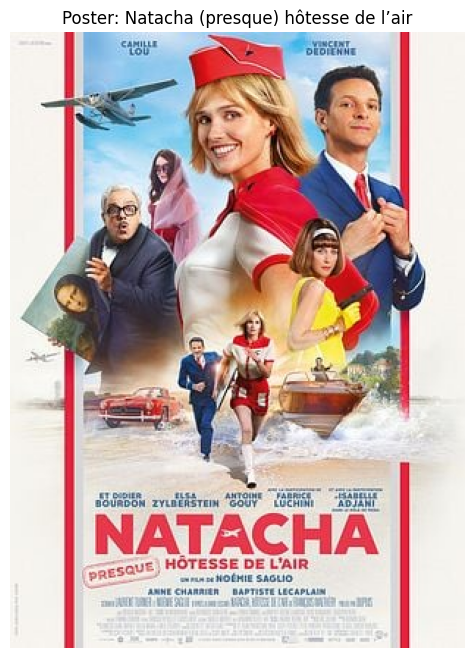

In [5]:
# Download poster
if not os.path.exists(poster_path):
    utils.download_poster_from_link(row['poster_url'], poster_path)
    print(f"Downloaded poster to {poster_path}")
else:
    print(f"Poster already exists at {poster_path}")

# Download trailer
if not os.path.exists(trailer_path):
    utils.download_video_from_link(row['trailer_url'], trailer_path)
    print(f"Downloaded trailer to {trailer_path}")
else:
    print(f"Trailer already exists at {trailer_path}")

# Display poster
poster = cv2.imread(poster_path)
poster_rgb = cv2.cvtColor(poster, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(6, 8))
plt.imshow(poster_rgb)
plt.axis('off')
plt.title(f"Poster: {row['allocine_title']}")
plt.show()

## Step 3: Extract Frames from Trailer

Extract all frames from the video file.

In [6]:
# Extract frames
frames, fps = utils.frame_capture(trailer_path)
print(f"Extracted {len(frames)} frames at {fps} FPS")
print(f"Frame shape: {frames[0].shape}")
print(f"Video duration: {len(frames)/fps:.2f} seconds")

Extracted 2407 frames at 24.0 FPS
Frame shape: (480, 848, 3)
Video duration: 100.29 seconds


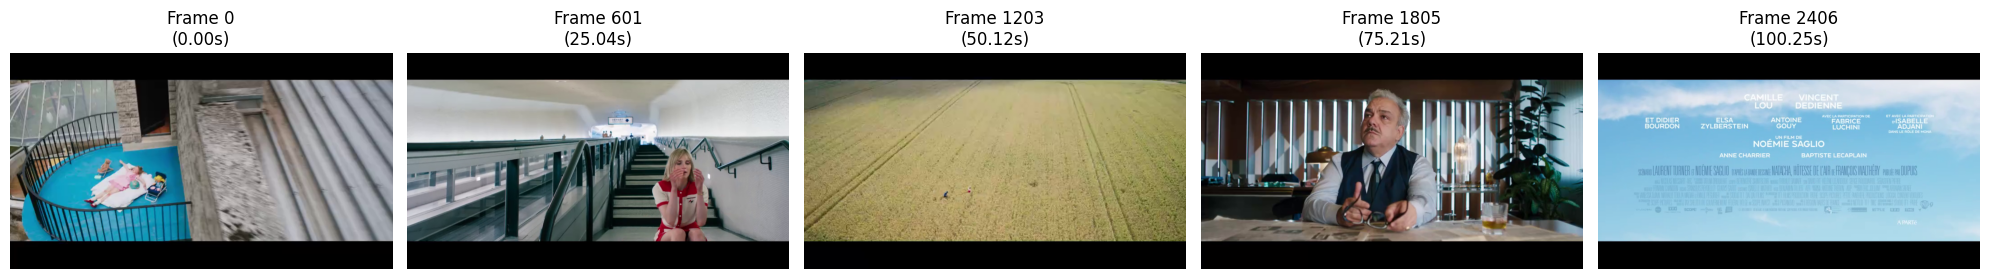

In [7]:
# Display a few sample frames
sample_indices = [0, len(frames)//4, len(frames)//2, 3*len(frames)//4, len(frames)-1]
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for idx, frame_idx in enumerate(sample_indices):
    frame_rgb = cv2.cvtColor(frames[frame_idx], cv2.COLOR_BGR2RGB)
    axes[idx].imshow(frame_rgb)
    axes[idx].set_title(f"Frame {frame_idx}\n({frame_idx/fps:.2f}s)")
    axes[idx].axis('off')
plt.tight_layout()
plt.show()

## Step 4: Detect Faces in Frames

Use YOLO face detection model to find all faces in the trailer frames.

In [8]:
# Compute video constants
H_original, W_original, effective_area, _, _ = utils.compute_constants(
    frames, movie_id=movie_id, source_type="trailer", mode="infer"
)
print(f"Video dimensions: {W_original}x{H_original}")
print(f"Effective area: {effective_area}")

Video dimensions: 848x480
Effective area: 290195.3188054883


In [9]:
# Check and verify model files exist
import os.path as osp

model_dir = osp.abspath('../models')
required_models = ['yolo11l.pt', 'yolov11n-face.pt', 'res34_fair_align_multi_7_20190809.pt']

print(f"Model directory: {model_dir}")
print(f"Model directory exists: {osp.exists(model_dir)}")
print("\nChecking required models:")
for model in required_models:
    model_path = osp.join(model_dir, model)
    exists = osp.exists(model_path)
    print(f"  {model}: {'✓' if exists else '✗ MISSING'}")
    if not exists:
        print(f"    Expected at: {model_path}")

Model directory: /home/Jojo/13_reveler_inegalites_cinema/ml-image/models
Model directory exists: True

Checking required models:
  yolo11l.pt: ✓
  yolov11n-face.pt: ✓
  res34_fair_align_multi_7_20190809.pt: ✓


In [10]:
# Change working directory to ml-image root to ensure model paths work
original_cwd = os.getcwd()
ml_image_root = os.path.abspath('..')
os.chdir(ml_image_root)
print(f"Changed working directory from: {original_cwd}")
print(f"                           to: {os.getcwd()}")
print(f"\nThis ensures model paths in scripts/vision_detection.py work correctly.")

Changed working directory from: /home/Jojo/13_reveler_inegalites_cinema/ml-image/notebooks
                           to: /home/Jojo/13_reveler_inegalites_cinema/ml-image

This ensures model paths in scripts/vision_detection.py work correctly.


In [11]:
from pathlib import Path

# Detect faces
batch_size = 32
num_cpu = 8

# Check if detections are already saved
detections_pkl_path = f"{downloaded_media_path}/{movie_id}_detections.pkl"

if os.path.exists(detections_pkl_path):
    print(f"Loading existing detections from {detections_pkl_path}")
    with open(detections_pkl_path, 'rb') as f:
        detections = pkl.load(f)
    print(f"Loaded {len(detections)} detections from cache")
else:
    print("Detecting faces in all frames...")
    detections = vision_detection.detect_faces(
        frames, H_original, W_original, area_type="face",
        batch_size=batch_size, device=device, num_cpu_threads=num_cpu
    )
    
    # Save detections to pickle
    print(f"Saving detections to {detections_pkl_path}")
    with open(detections_pkl_path, 'wb') as f:
        pkl.dump(detections, f)

print(f"Total detections: {len(detections)}")
print(f"Average detections per frame: {len(detections)/len(frames):.2f}")
print(f"Average detections per frame: {len(detections)/len(frames):.2f}")

Detecting faces in all frames...
Saving detections to ../tmp/downloaded_media/159573_detections.pkl
Total detections: 4108
Average detections per frame: 1.71
Average detections per frame: 1.71


In [12]:
# Analyze detection statistics
frames_with_faces = set([d['frame_id'] for d in detections])
print(f"Frames with at least one face: {len(frames_with_faces)}/{len(frames)} ({len(frames_with_faces)/len(frames)*100:.1f}%)")

# Count faces per frame
from collections import Counter
faces_per_frame = Counter([d['frame_id'] for d in detections])
print(f"\nFaces per frame statistics:")
print(f"  Min: {min(faces_per_frame.values()) if faces_per_frame else 0}")
print(f"  Max: {max(faces_per_frame.values()) if faces_per_frame else 0}")
print(f"  Mean: {np.mean(list(faces_per_frame.values())) if faces_per_frame else 0:.2f}")


Frames with at least one face: 1750/2407 (72.7%)

Faces per frame statistics:
  Min: 1
  Max: 23
  Mean: 2.35


## Step 5: Filter Detections for Classification

Filter out low-quality detections based on area, confidence, etc.

In [13]:
# Filter parameters (using default values from main.py)
min_area = 0.076  # Minimum face area relative to frame
max_area = 1.0
min_conf = 0.0  # Minimum detection confidence

print(f"Filtering detections with:")
print(f"  min_area: {min_area}")
print(f"  max_area: {max_area}")
print(f"  min_conf: {min_conf}")

filtered_detections_for_classification = filter_detections.filter_detections_clustering(
    detections, effective_area, min_area, max_area, min_conf, remove_overlaps=True
)

print(f"\nDetections after filtering: {len(filtered_detections_for_classification)} ({len(filtered_detections_for_classification)/len(detections)*100:.1f}% kept)")

Filtering detections with:
  min_area: 0.076
  max_area: 1.0
  min_conf: 0.0

Detections after filtering: 244 (5.9% kept)


In [14]:
detections[0].keys()

dict_keys(['bbox', 'conf', 'frame_id', 'perso_id', 'cropped_face'])


frame_id=871:
  Detection bbox: [378, 104, 506, 255], area: 19328 (0.0666 of effective), confidence: 0.87 -> DISCARD


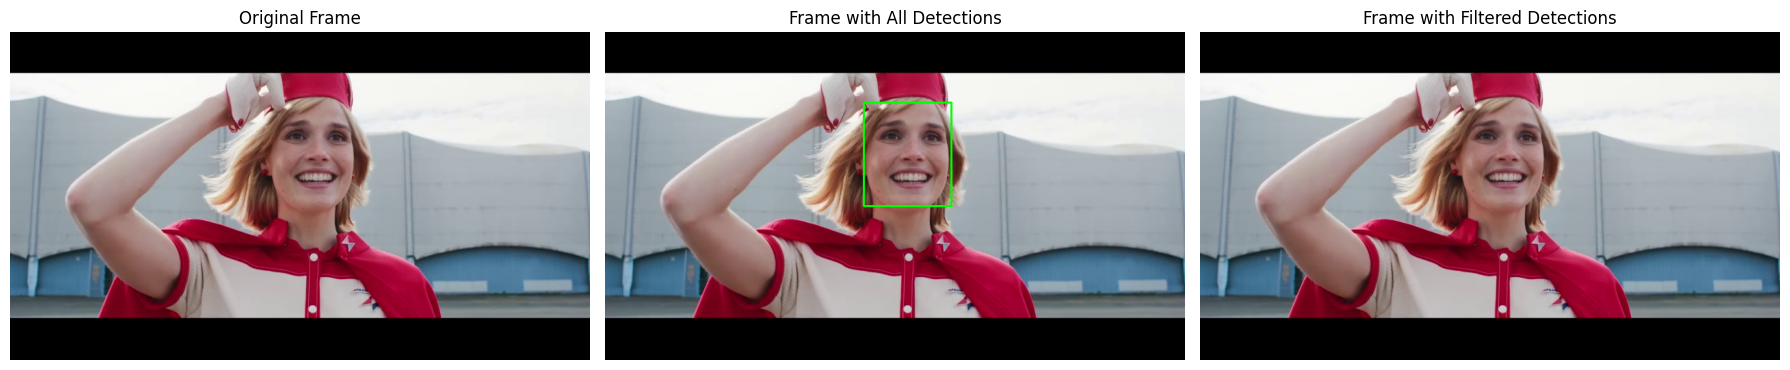

In [15]:
frame_id = 871#2308 
# for frame_id, show filtering details
print(f"\nframe_id={frame_id}:")

detection_frame_id = [det for det in detections if det['frame_id'] == frame_id]
for det in detection_frame_id:
    x1, y1, x2, y2 = det['bbox']
    bbox_area = (x2 - x1) * (y2 - y1)
    relative_area = bbox_area / effective_area
    conf = det['conf']
    keep = (relative_area >= min_area) and (relative_area <= max_area) and (conf >= min_conf)
    print(f"  Detection bbox: {det['bbox']}, area: {bbox_area} ({relative_area:.4f} of effective), confidence: {conf:.2f} -> {'KEEP' if keep else 'DISCARD'}")

# show frame with detections and frame with filtered detections (use subplots)

original_frame = frames[frame_id].copy()
frame_with_detections = original_frame.copy()
frame_with_filtered_detections = original_frame.copy()
for det in detections:
    if det['frame_id'] == frame_id:
        x1, y1, x2, y2 = map(int, det['bbox'])
        cv2.rectangle(frame_with_detections, (x1, y1), (x2, y2), (0, 255, 0), 2)
for det in filtered_detections_for_classification:
    if det['frame_id'] == frame_id:
        x1, y1, x2, y2 = map(int, det['bbox'])
        cv2.rectangle(frame_with_filtered_detections, (x1, y1), (x2, y2), (0, 255, 0), 2)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(cv2.cvtColor(original_frame, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Frame")
axes[0].axis('off')
axes[1].imshow(cv2.cvtColor(frame_with_detections, cv2.COLOR_BGR2RGB))
axes[1].set_title("Frame with All Detections")
axes[1].axis('off')
axes[2].imshow(cv2.cvtColor(frame_with_filtered_detections, cv2.COLOR_BGR2RGB))
axes[2].set_title("Frame with Filtered Detections")
axes[2].axis('off')
plt.tight_layout()
plt.show()


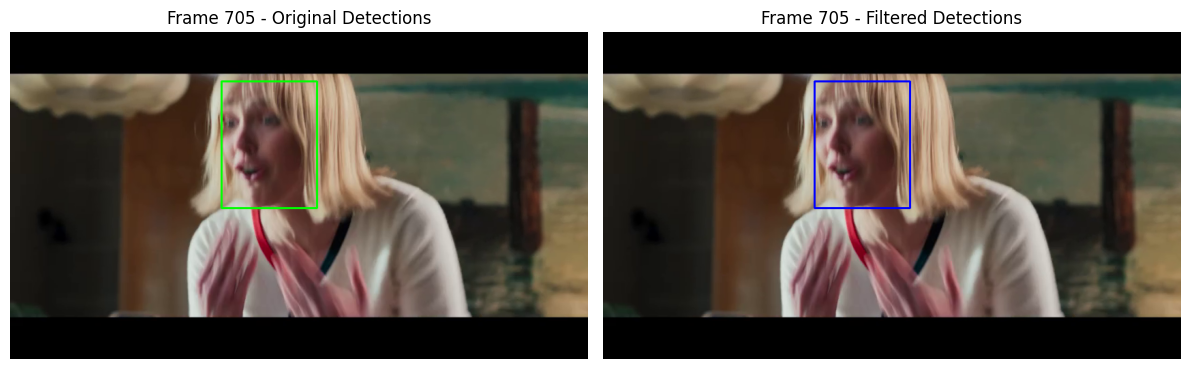

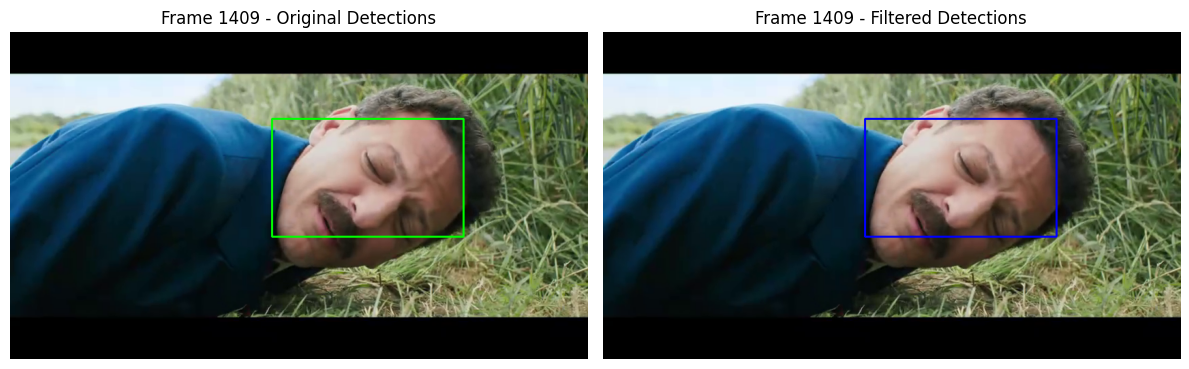

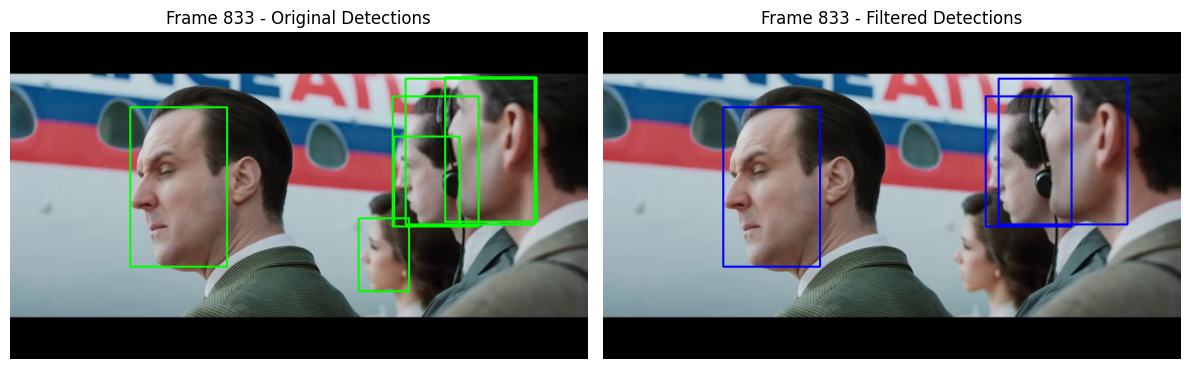

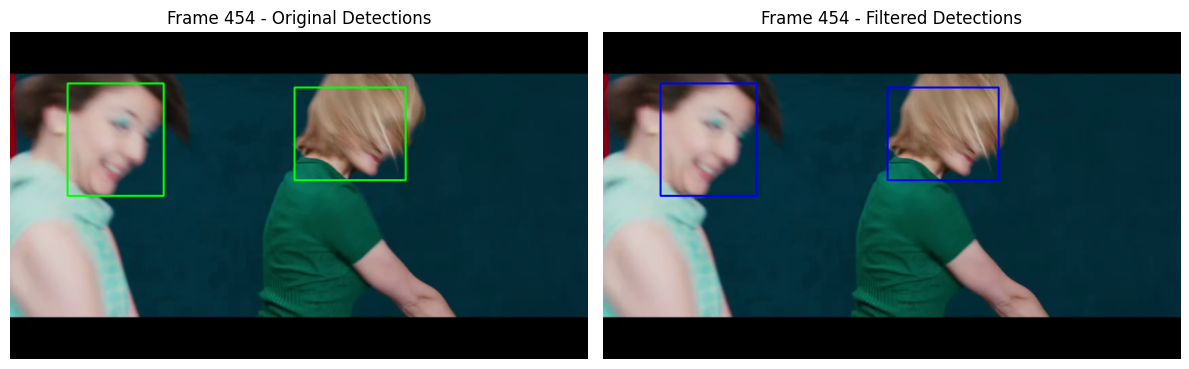

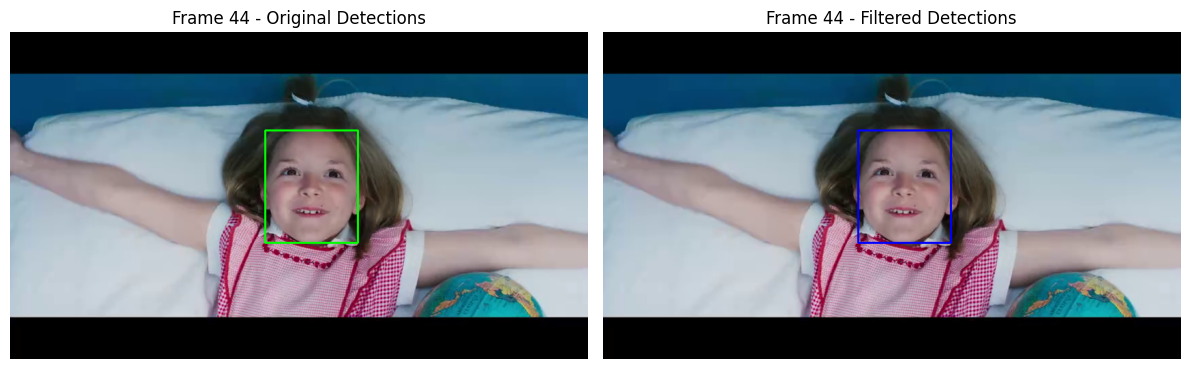

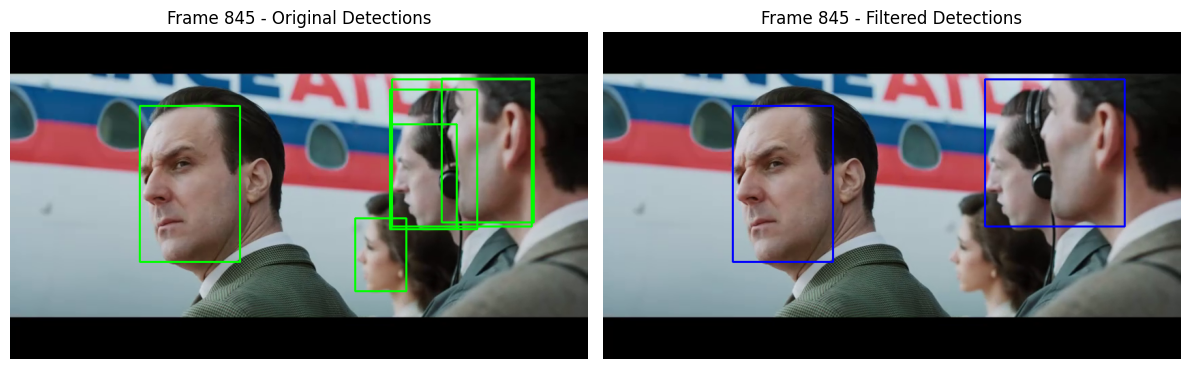

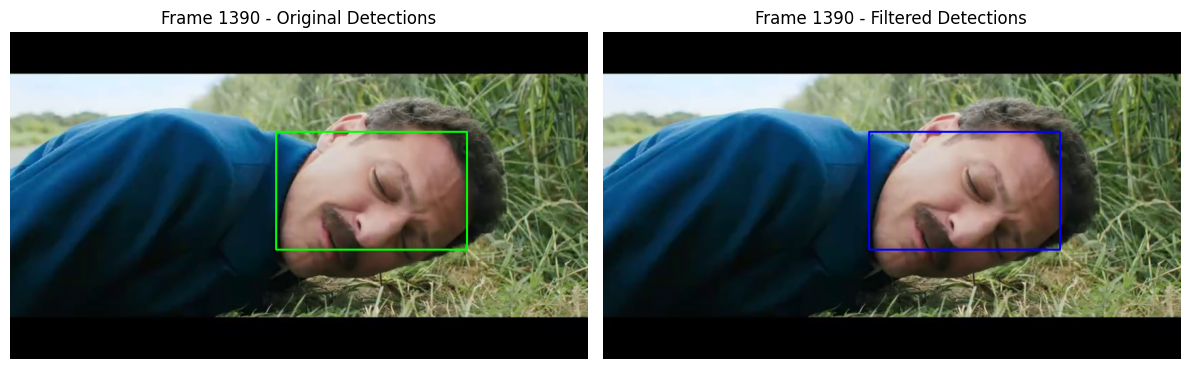

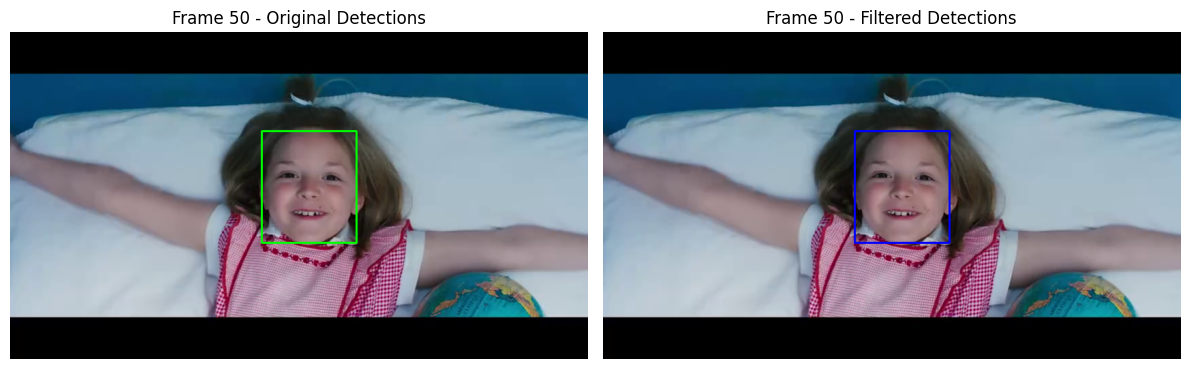

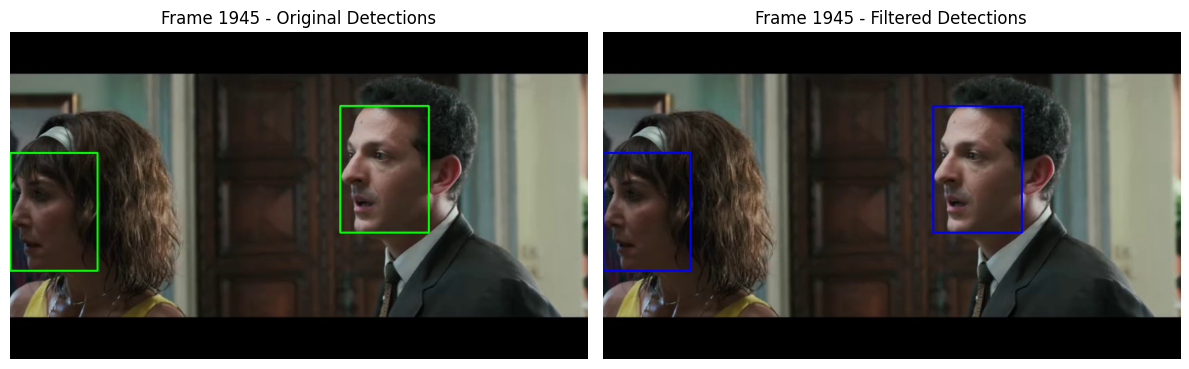

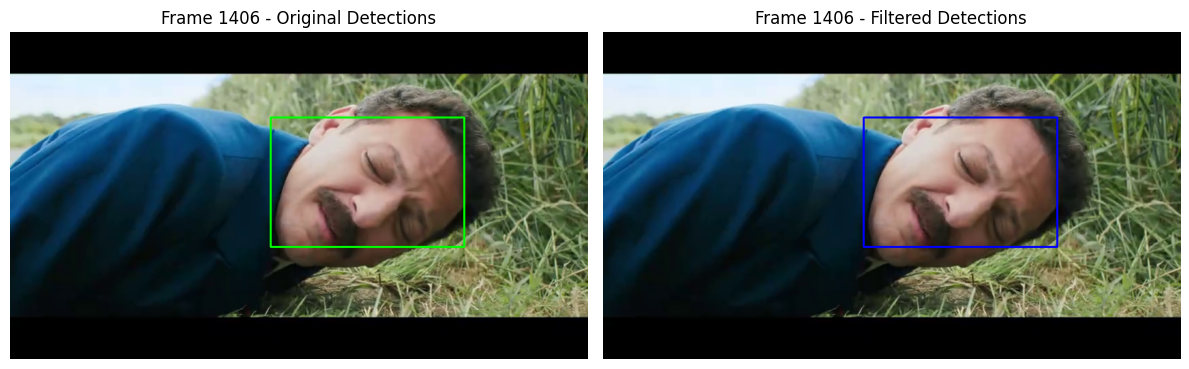

In [16]:
# show frame with detections and frame with filtered detections (use subplots)

# filtered_detections_for_classification[0]
# {'bbox': [369, 134, 507, 297],
#  'conf': 0.8818359375,
#  'frame_id': 36,
#  'perso_id': 0,
#  'cropped_face': array([[[ 59,  66,  59],
#          [ 59,  67,  57],
#          [ 59,  67,  57],
#          ...,

# get N random frame_ids

N = 10
import random
random_indices = random.sample(range(len(filtered_detections_for_classification)), N)
random_frame_ids = set([filtered_detections_for_classification[i]['frame_id'] for i in random_indices])

for i in random_frame_ids:
    sample_frame_id = i     
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    
    frame_detections = [d for d in detections if d['frame_id'] == sample_frame_id]
    frame_filtered_detections = [d for d in filtered_detections_for_classification if d['frame_id'] == sample_frame_id]
    
    # Original detections
    sample_frame = frames[sample_frame_id].copy()
    for det in frame_detections:
        x1, y1, x2, y2 = map(int, det['bbox'])
        cv2.rectangle(sample_frame, (x1, y1), (x2, y2), (0, 255, 0), 2)

    axes[0].imshow(cv2.cvtColor(sample_frame, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"Frame {sample_frame_id} - Original Detections")
    axes[0].axis('off') 
    
    # Filtered detections
    sample_frame_filtered = frames[sample_frame_id].copy()
    for det in frame_filtered_detections:
        x1, y1, x2, y2 = map(int, det['bbox'])
        cv2.rectangle(sample_frame_filtered, (x1, y1), (x2, y2), (255, 0, 0), 2)
    axes[1].imshow(cv2.cvtColor(sample_frame_filtered, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f"Frame {sample_frame_id} - Filtered Detections")
    axes[1].axis('off')
    plt.tight_layout()
    plt.show()
    

## Step 6: Classify Faces

Use FairFace classifier to predict age, gender, and ethnicity for each detected face.

In [17]:
# Classify faces
print("Classifying faces for age, gender, and ethnicity...")
classified_faces, flattened_faces = vision_classifiers.classify_faces(
    filtered_detections_for_classification, batch_size=batch_size, device=device
)

print(f"Classified {len(classified_faces)} faces")
print(f"Flattened faces array shape: {len(flattened_faces)}")

Classifying faces for age, gender, and ethnicity...
Classified 244 faces
Flattened faces array shape: 244


In [18]:
# Analyze classification results
if classified_faces:
    
    # Count demographics
    genders = [f['gender'] for f in classified_faces]
    ages = [f['age'] for f in classified_faces]
    ethnicities = [f['ethnicity'] for f in classified_faces]
    
    print(f"\nGender distribution:")
    for gender, count in Counter(genders).most_common():
        print(f"  {gender}: {count} ({count/len(genders)*100:.1f}%)")
    
    print(f"\nAge distribution:")
    for age, count in Counter(ages).most_common():
        print(f"  {age}: {count} ({count/len(ages)*100:.1f}%)")
    
    print(f"\nEthnicity distribution:")
    for ethnicity, count in Counter(ethnicities).most_common():
        print(f"  {ethnicity}: {count} ({count/len(ethnicities)*100:.1f}%)")


Gender distribution:
  unknown: 126 (51.6%)
  Male: 71 (29.1%)
  Female: 47 (19.3%)

Age distribution:
  20-29: 132 (54.1%)
  unknown: 90 (36.9%)
  3-9: 21 (8.6%)
  30-39: 1 (0.4%)

Ethnicity distribution:
  White: 189 (77.5%)
  unknown: 55 (22.5%)


## Step 7: Filter Detections for Clustering

Apply additional quality filters before clustering (sharpness, pose, etc.).

In [19]:
# Advanced filter parameters
min_conf_cla = 0.806  # Minimum classification confidence
min_sharpness_cla = 144.4  # Minimum sharpness score
max_z_cla = -0.182  # Maximum nose z-coordinate (pose filter)
min_mouth_opening_cla = 0.0  # Minimum mouth opening

print(f"Applying advanced filters:")
print(f"  min_conf_cla: {min_conf_cla}")
print(f"  min_sharpness_cla: {min_sharpness_cla}")
print(f"  max_z_cla: {max_z_cla}")
print(f"  min_mouth_opening_cla: {min_mouth_opening_cla}")

filtered_detections_for_clustering = filter_detections.filter_detections_classifications(
    classified_faces, effective_area, min_conf_cla, min_sharpness_cla, 
    max_z_cla, min_mouth_opening_cla, movie_id=movie_id, mode="infer"
)

print(f"\nFaces after quality filtering: {len(filtered_detections_for_clustering)} ({len(filtered_detections_for_clustering)/len(classified_faces)*100:.1f}% kept)")

Applying advanced filters:
  min_conf_cla: 0.806
  min_sharpness_cla: 144.4
  max_z_cla: -0.182
  min_mouth_opening_cla: 0.0


W0000 00:00:1762273901.669299   18331 landmark_projection_calculator.cc:186] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.



Faces after quality filtering: 244 (100.0% kept)


## Step 8: Embed Faces

Convert face images to 512-dimensional embeddings using FaceNet.

This step creates a numerical representation of each face that captures its unique features. Faces of the same person will have similar embeddings.

In [20]:
# Embed faces using FaceNet
print("Embedding faces using FaceNet...")
embedded_faces = faces_clustering.embed_faces(
    flattened_faces, batch_size=batch_size, device=device
)

print(f"Embeddings shape: {embedded_faces.shape}")
print(f"Each face is represented as a {embedded_faces.shape[1]}-dimensional vector")

Embedding faces using FaceNet...
Embeddings shape: (244, 512)
Each face is represented as a 512-dimensional vector


Embedding statistics:
  Mean: 0.0010
  Std: 0.0442
  Min: -0.1657
  Max: 0.1742


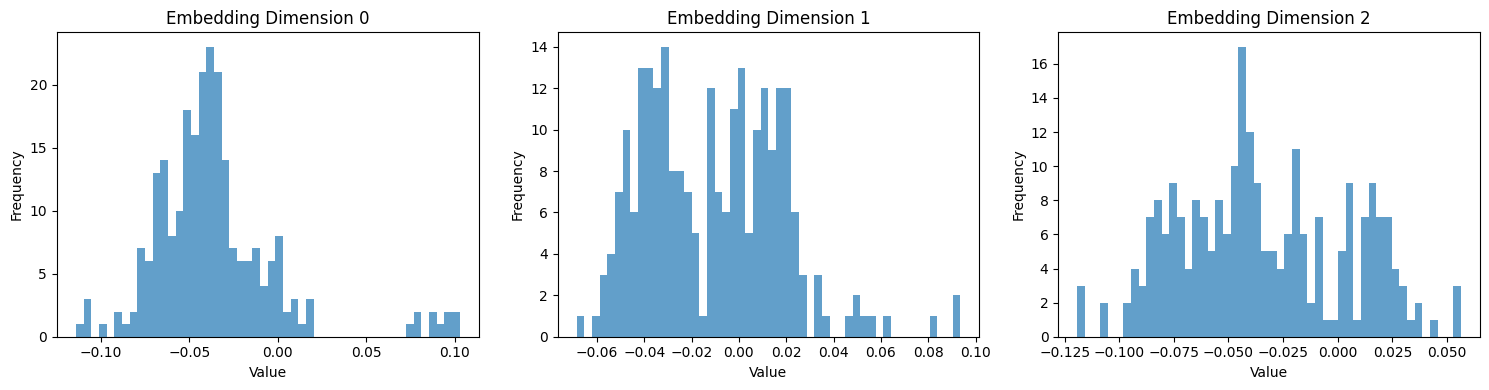

In [21]:
# Visualize embedding statistics
print("Embedding statistics:")
print(f"  Mean: {embedded_faces.mean():.4f}")
print(f"  Std: {embedded_faces.std():.4f}")
print(f"  Min: {embedded_faces.min():.4f}")
print(f"  Max: {embedded_faces.max():.4f}")

# Plot distribution of first few dimensions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i in range(3):
    axes[i].hist(embedded_faces[:, i], bins=50, alpha=0.7)
    axes[i].set_title(f"Embedding Dimension {i}")
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")
plt.tight_layout()
plt.show()

## Step 9: Cluster Faces

Use Chinese Whispers clustering to group similar faces together. Each cluster represents a unique character.

**How it works:**
- Compares face embeddings using distance metrics
- Groups faces with distance < threshold (default: 0.92) as the same person
- Aggregates predictions per character using weighted voting

In [22]:
# Cluster parameters
cluster_model = "chinese_whispers"
cluster_threshold = 0.92
agr_method = "majority"

print(f"Clustering faces with:")
print(f"  Model: {cluster_model}")
print(f"  Threshold: {cluster_threshold}")
print(f"  Aggregation method: {agr_method}")

# Perform clustering
aggregated_estimations = faces_clustering.cluster_faces(
    embedded_faces, 
    model=cluster_model, 
    threshold=cluster_threshold, 
    classified_faces=filtered_detections_for_clustering,
    method=agr_method, 
    fps=fps, 
    effective_area=effective_area
)

print(f"\nIdentified {len(aggregated_estimations)} unique characters")

Clustering faces with:
  Model: chinese_whispers
  Threshold: 0.92
  Aggregation method: majority

Identified 7 unique characters


In [23]:
# clustering output 

# aggregated_estimations[0]

# {'age': '3-9',
#  'gender': 'unknown',
#  'ethnicity': 'White',
#  'occurence': 0.875,
#  'area occupied': 0.07750789593716625,
#  'label': 0,
#  'frames_bboxes': {36: [369, 134, 507, 297],
#   37: [371, 135, 508, 299],
#   38: [372, 137, 508, 300],
#   39: [372, 138, 510, 300],
#   ...},
#   'persons_ids': [0,
#   1,
#   2,
#   3,
#   ... ]}

CHARACTER ANALYSIS FOR: Natacha (presque) hôtesse de l’air

Character 1:
  Gender: unknown
  Age: 3-9
  Ethnicity: White
  Time on screen: 0.88 seconds
  Average size on screen: 0.0775
  Number of appearances: 21 frames
  Percentage of total detections: 8.6%


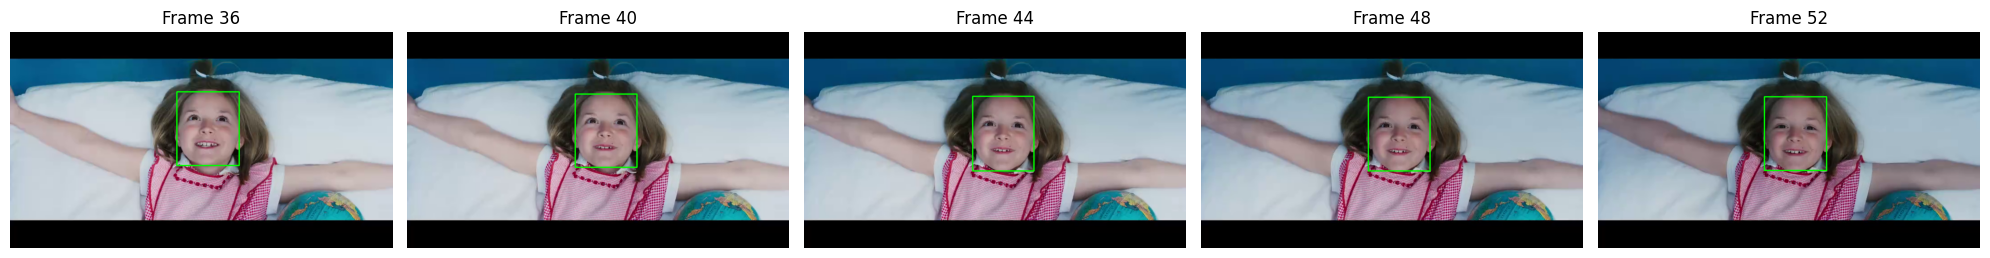


Character 2:
  Gender: unknown
  Age: 20-29
  Ethnicity: White
  Time on screen: 3.46 seconds
  Average size on screen: 0.1614
  Number of appearances: 83 frames
  Percentage of total detections: 34.0%


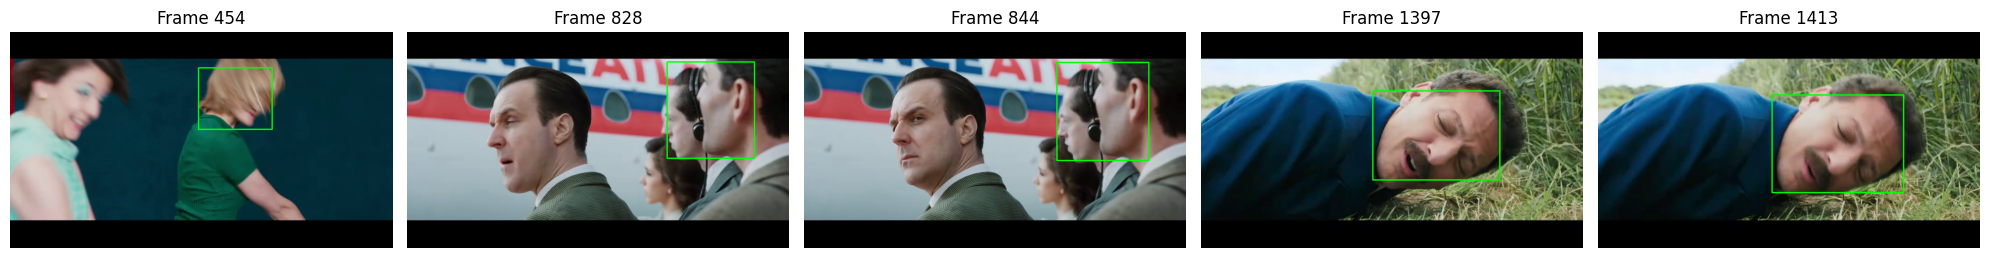


Character 3:
  Gender: Female
  Age: 20-29
  Ethnicity: White
  Time on screen: 1.21 seconds
  Average size on screen: 0.0959
  Number of appearances: 29 frames
  Percentage of total detections: 11.9%


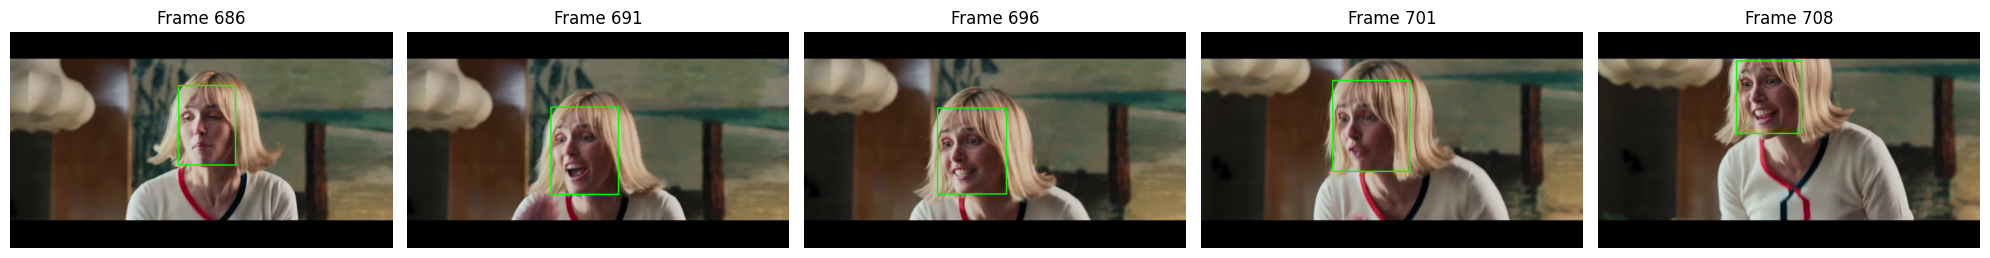


Character 4:
  Gender: Male
  Age: 20-29
  Ethnicity: White
  Time on screen: 1.46 seconds
  Average size on screen: 0.1179
  Number of appearances: 35 frames
  Percentage of total detections: 14.3%


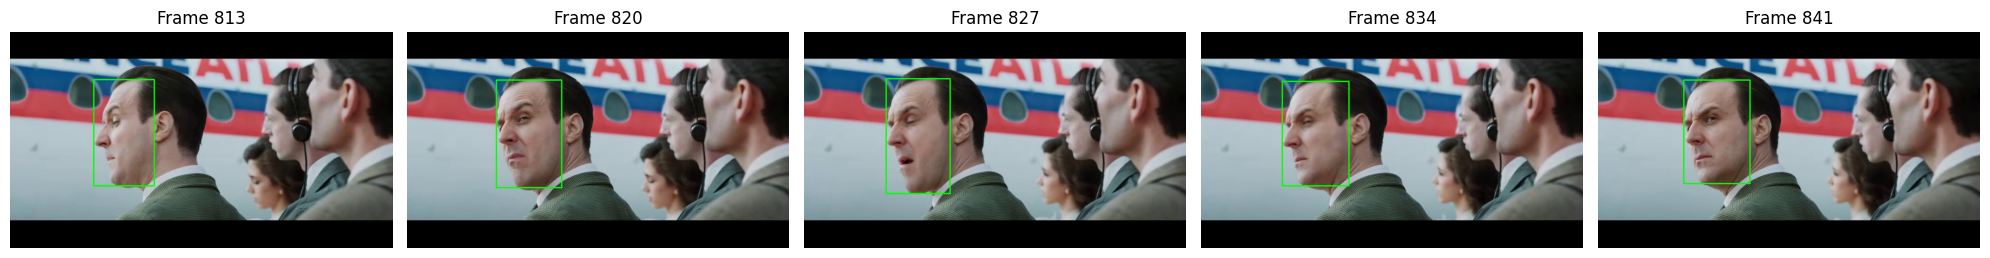


Character 5:
  Gender: Male
  Age: 20-29
  Ethnicity: White
  Time on screen: 1.08 seconds
  Average size on screen: 0.0850
  Number of appearances: 26 frames
  Percentage of total detections: 10.7%


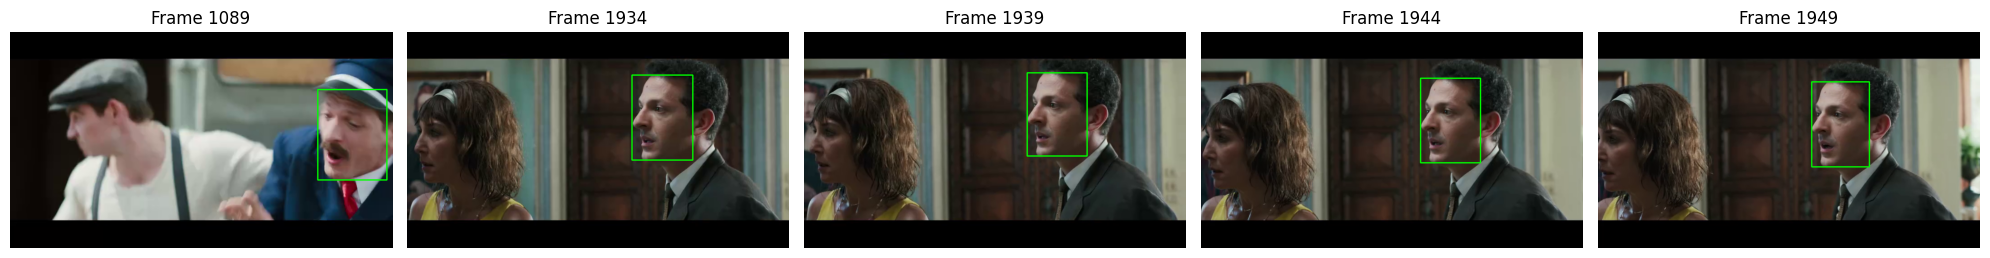


Character 6:
  Gender: Female
  Age: 20-29
  Ethnicity: White
  Time on screen: 0.96 seconds
  Average size on screen: 0.0941
  Number of appearances: 23 frames
  Percentage of total detections: 9.4%


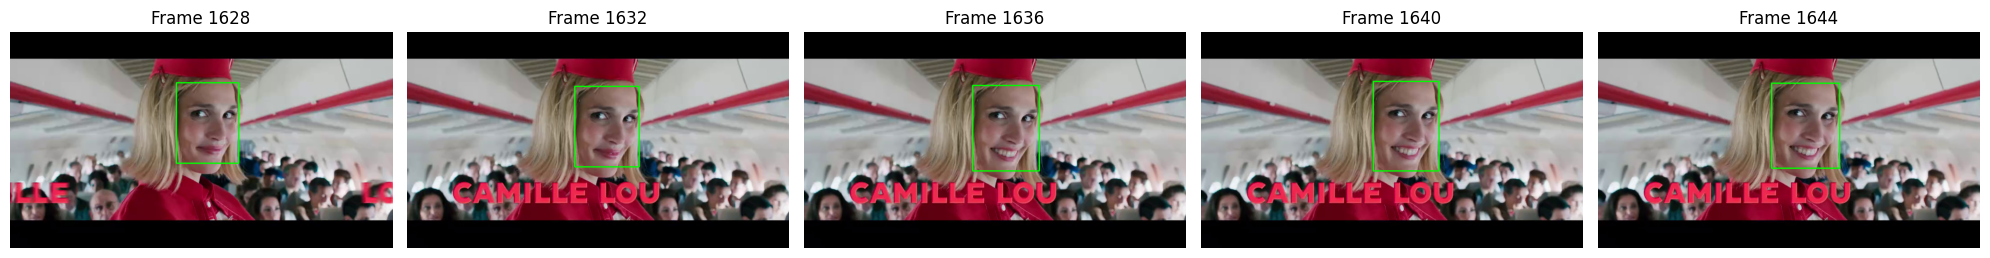


Character 7:
  Gender: Male
  Age: unknown
  Ethnicity: White
  Time on screen: 0.42 seconds
  Average size on screen: 0.0792
  Number of appearances: 10 frames
  Percentage of total detections: 4.1%


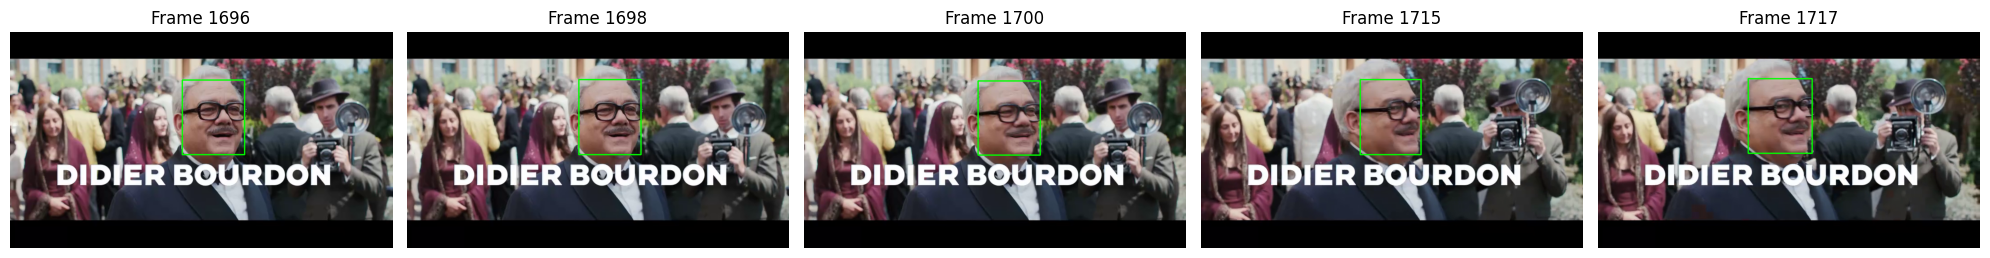

In [24]:
# Display character information
print("=" * 80)
print(f"CHARACTER ANALYSIS FOR: {row['allocine_title']}")
print("=" * 80)

for idx, char in enumerate(aggregated_estimations):
    print(f"\nCharacter {idx + 1}:")
    print(f"  Gender: {char['gender']}")
    print(f"  Age: {char['age']}")
    print(f"  Ethnicity: {char['ethnicity']}")
    print(f"  Time on screen: {char['occurence']:.2f} seconds")
    print(f"  Average size on screen: {char['area occupied']:.4f}")
    print(f"  Number of appearances: {len(char['persons_ids'])} frames")
    print(f"  Percentage of total detections: {len(char['persons_ids'])/len(filtered_detections_for_clustering)*100:.1f}%")
    
    # show 5 different frames evenly spaced where the character appears
    sample_frame_ids = sorted(char['frames_bboxes'].keys())
    if len(sample_frame_ids) > 5:
        step = len(sample_frame_ids) // 5
        sample_frame_ids = sample_frame_ids[::step][:5]
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    for i, frame_id in enumerate(sample_frame_ids):
        frame = frames[frame_id].copy()
        x1, y1, x2, y2 = map(int, char['frames_bboxes'][frame_id])
        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
        axes[i].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        axes[i].set_title(f"Frame {frame_id}")
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

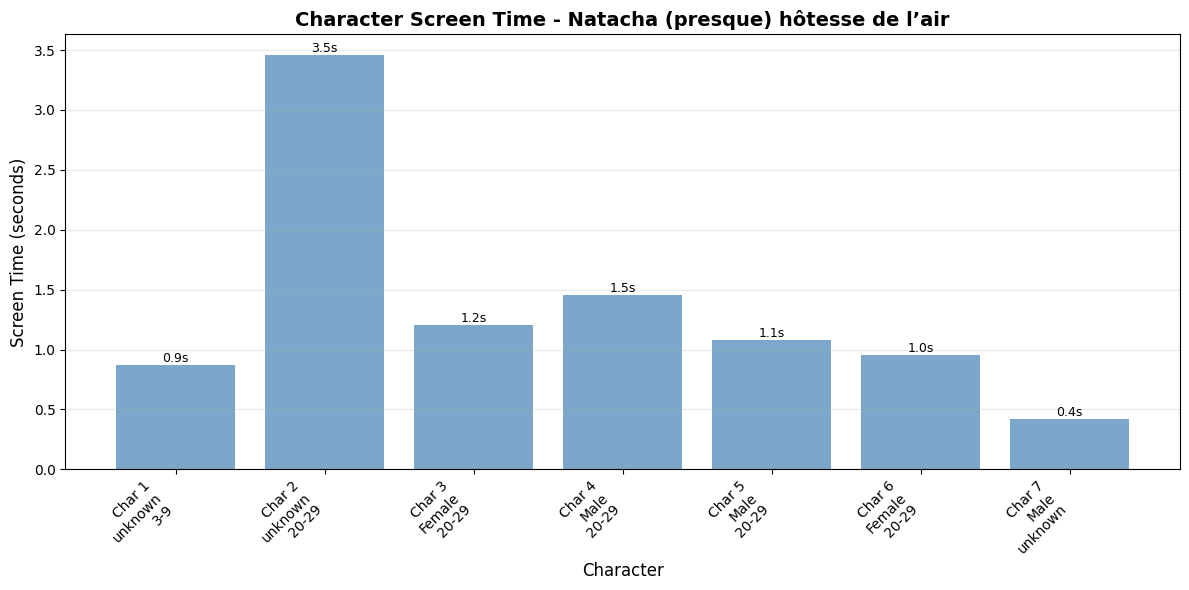

In [25]:
# Visualize character screen time
if aggregated_estimations:
    char_labels = [f"Char {i+1}\n{c['gender']}\n{c['age']}" 
                   for i, c in enumerate(aggregated_estimations)]
    screen_times = [c['occurence'] for c in aggregated_estimations]
    
    plt.figure(figsize=(12, 6))
    bars = plt.bar(char_labels, screen_times, color='steelblue', alpha=0.7)
    plt.xlabel('Character', fontsize=12)
    plt.ylabel('Screen Time (seconds)', fontsize=12)
    plt.title(f'Character Screen Time - {row["allocine_title"]}', fontsize=14, fontweight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', alpha=0.3)
    
    # Add value labels on bars
    for bar, time in zip(bars, screen_times):
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height,
                f'{time:.1f}s',
                ha='center', va='bottom', fontsize=9)
    
    plt.tight_layout()
    plt.show()

## Summary

This notebook demonstrated the complete pipeline from loading film data to identifying and analyzing characters through face clustering.

**Key Steps:**
1. ✅ Loaded film metadata from CSV
2. ✅ Downloaded poster and trailer
3. ✅ Extracted frames from video
4. ✅ Detected faces using YOLO
5. ✅ Filtered low-quality detections
6. ✅ Classified faces for demographics (FairFace)
7. ✅ Embedded faces into feature vectors (FaceNet)
8. ✅ Clustered similar faces (Chinese Whispers)
9. ✅ Aggregated character-level statistics

**Next Steps:**
- Apply the same process to poster images
- Match poster faces to trailer characters
- Save predictions for database insertion